In [123]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import scipy.special as sp
%matplotlib inline
plt.rcParams['figure.figsize'] = (10,10)
from multiprocess import Pool
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [124]:
HST_data = {
    'M1': {
        'Radius': 11040.,
        'Conic': -1.0022985,
        'Aperture': 2 * 1200.,
        'Obscuration':{
            'Inner': 2 * 350.,
            'Arm size': 25.,
            'Arm number': 4
        }
    },
    'M2': {
        'Radius': 1358.,
        'Conic': -1.49600,
        'Aperture': 2 * 150.
    },
    'Spacings': {
        'BFD': 1500.,
        'Separation': 4906.072
    }
}

def telescopeCreation(WL, dx, dy, dz, tx, ty, tz):
    #global WL
    global telescope, M1

    global outter1, inner1, outterD
    
    K = 1000 #meter conversion from mm
        ##############################

        ### Primary ###
    R1, conic1, inner1, outter1 = -HST_data['M1']['Radius']/K, HST_data['M1']['Conic'], HST_data['M1']['Obscuration']['Inner']/K, HST_data['M1']['Aperture']/K
    M1coord = defineCoordinate().local()
    M1 = optic('M1', type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(4, 0.025)
        ###############

        ### Seconday ###
    R2, conic2, outter2 = -HST_data['M2']['Radius']/K, HST_data['M2']['Conic'], HST_data['M2']['Aperture']/K
    pos2 = -HST_data['Spacings']['Separation']/K
    M2coord = defineCoordinate(posX=dx/K, posY=dy/K, posZ=pos2+dz/K, anglX=tx, anglY=ty, anglZ=tz).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()
        ################

        ### Detector ###
    outterD = 1
    posD = HST_data['Spacings']['BFD']/K
    Dcoord = defineCoordinate(posZ=posD).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()
        ################

        ### HST ###
    telescope = build.compoundOptic(M1, M2, D,
                                   pupilSize=outter1, backDist=6,
                                   EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [125]:
%run Batoid4LOFT.ipynb
telescope = telescopeCreation(650e-9, dx=0, dy=0, dz=0.01, tx=0, ty=0, tz=0)
infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=650e-9)
PSFNA, StehlRatioNA = infoTelescope.fftPSF(npx=128, pad=16)

In [126]:
def model(theta):
    dx, dy, dz, tx, ty = theta
    %run Batoid4LOFT.ipynb
    telescope = telescopeCreation(650e-9, dx=dx, dy=dy, dz=dz, tx=tx, ty=ty, tz=0)
    infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=650e-9)
    PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
    return PSF

In [127]:
def lnlike(theta, y, yerr):
    return -0.5 * np.sum(((y - model(theta))/yerr) ** 2)

In [128]:
def lnprior(theta):
    dx, dy, dz, tx, ty = theta
    if -0.3 < dx < 0.3 and -0.9 < dy < 0.9 and -0.04 < dz < 0.04 and -0.08 < tx < 0.08 and -0.02 < ty < 0.02:
        return 0.0
    return -np.inf

In [129]:
def lnprob(theta, y, yerr):
    lp = lnprior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike(theta, y, yerr)

In [142]:
ierr = 0.05*np.mean(PSFNA)
data = (PSFNA, ierr)
nwalkers = 64
niter = 500
initial = np.array([0, 0, 0.01, 0, 0])
ndim = len(initial)
p0 = [np.array(initial) + 1e-7 * np.random.randn(ndim) for i in range(nwalkers)]

In [131]:
def main(p0,nwalkers,niter,ndim,lnprob,data):
    sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob, args=data, vectorize=False)

    print("Running burn-in...")
    p0, _, _ = sampler.run_mcmc(p0, 50, progress=True)
    sampler.reset()

    print("Running production...")
    pos, prob, state = sampler.run_mcmc(p0, niter, progress=True)

    return sampler, pos, prob, state

In [132]:
sampler, pos, prob, state = main(p0,nwalkers,niter,ndim,lnprob,data)

Running burn-in...
emcee: Exception while calling your likelihood function:
  params: [ 0.1         0.30000008 -0.01000009  0.01000006  0.01000002]
  args: (array([[5.41106292e-06, 5.38253886e-06, 5.29713735e-06, ...,
        5.15521870e-06, 5.29494483e-06, 5.38144841e-06],
       [5.40614290e-06, 5.37776545e-06, 5.29280389e-06, ...,
        5.15161868e-06, 5.29062502e-06, 5.37668189e-06],
       [5.34964536e-06, 5.32170446e-06, 5.23808946e-06, ...,
        5.09927122e-06, 5.23602332e-06, 5.32067743e-06],
       ...,
       [5.12515861e-06, 5.09793259e-06, 5.01662977e-06, ...,
        4.88222307e-06, 5.01495847e-06, 5.09710325e-06],
       [5.26769896e-06, 5.23976173e-06, 5.15622643e-06, ...,
        5.01776991e-06, 5.15429549e-06, 5.23880231e-06],
       [5.36427790e-06, 5.33590249e-06, 5.25098302e-06, ...,
        5.10998787e-06, 5.24887503e-06, 5.33485437e-06]]), 3.929994572528088e-06)
  kwargs: {}
  exception:


Traceback (most recent call last):
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/emcee/ensemble.py", line 624, in __call__
    return self.f(x, *self.args, **self.kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_69474/2091716942.py", line 5, in lnprob
    return lp + lnlike(theta, y, yerr)
                ^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_69474/3421641289.py", line 2, in lnlike
    return -0.5 * np.sum(((y - model(theta))/yerr) ** 2)
                               ^^^^^^^^^^^^
  File "/var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_69474/2655373768.py", line 3, in model
    get_ipython().run_line_magic('run', 'Batoid4LOFT.ipynb')
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 2417, in run_line_magic
    result = fn(*args, **kwargs)
             ^^^^^^^^^^^^^^^

KeyboardInterrupt: 

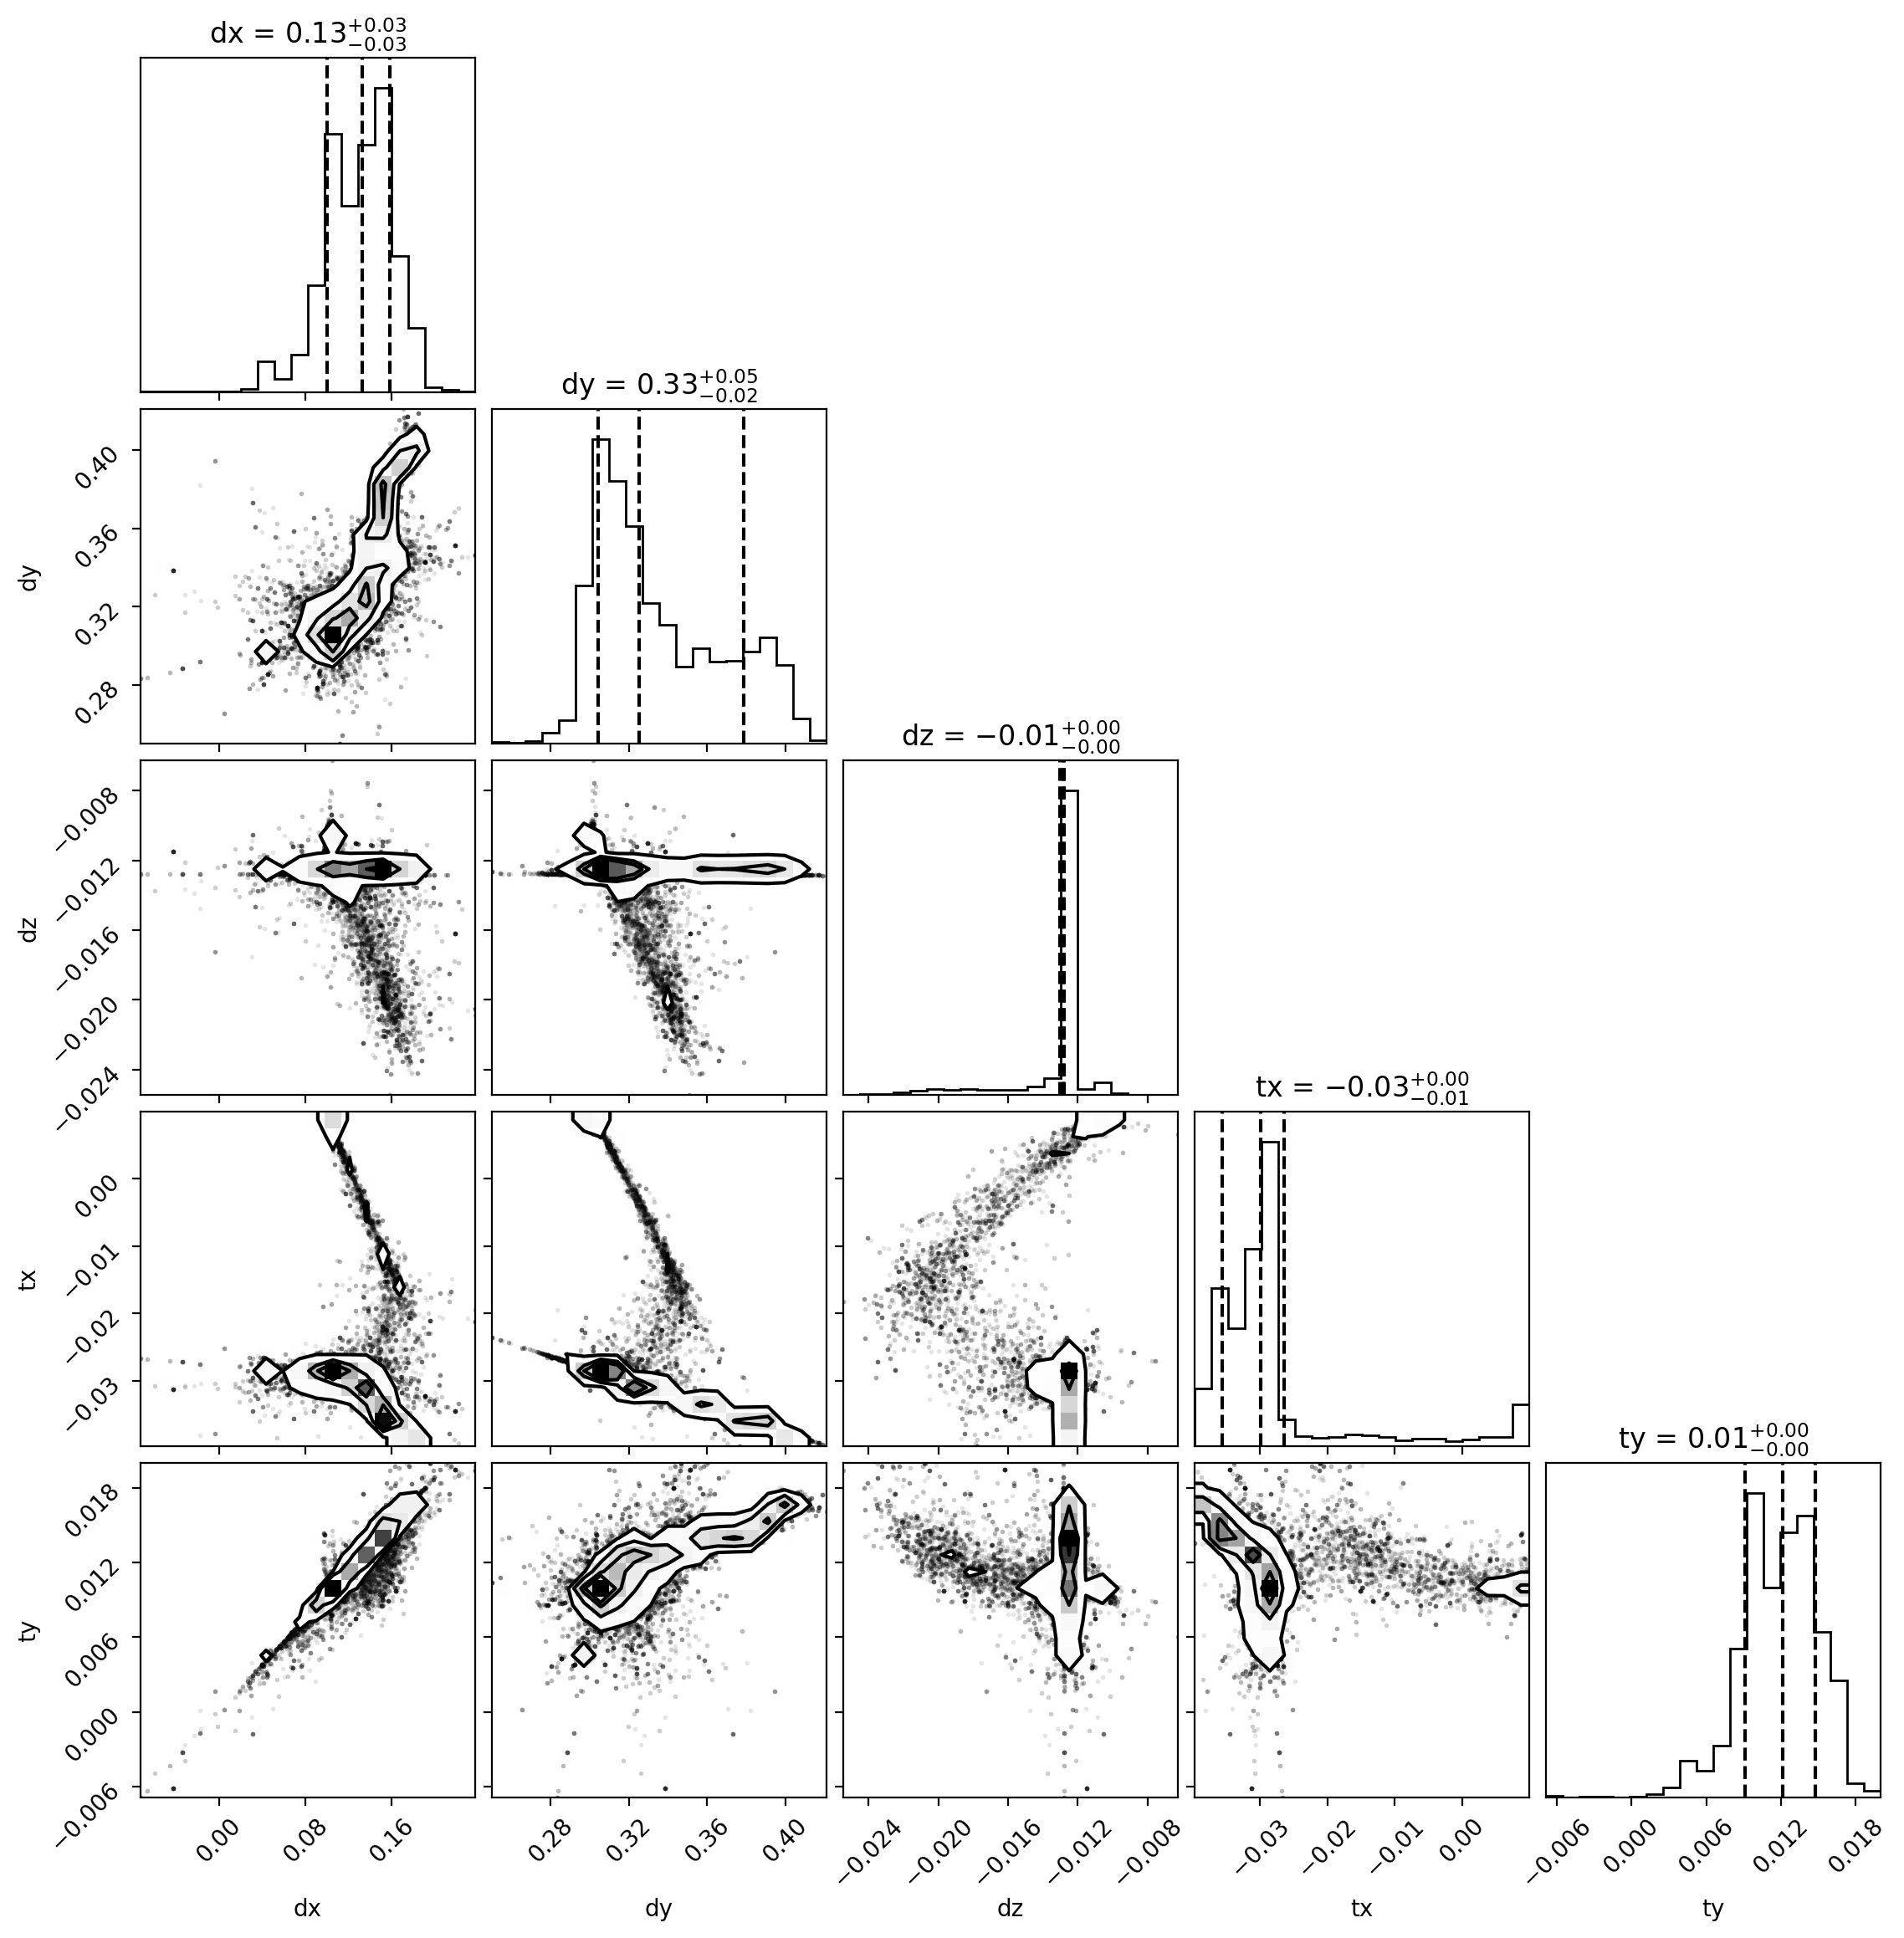

In [ ]:
samples = sampler.flatchain
labels = ['dx', 'dy', 'dz', 'tx', 'ty']
fig = corner.corner(samples,show_titles=True,labels=labels,plot_datapoints=True,quantiles=[0.16, 0.5, 0.84])

In [ ]:
print(
    "Mean acceptance fraction: {0:.3f}".format(
        np.mean(sampler.acceptance_fraction)
    )
)

Mean acceptance fraction: 0.368


In [ ]:
if __name__ == '__main__':
    with Pool(4) as pool:
        sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob, args=data, pool=pool)

        print("Running burn-in...")
        p0, _, _ = sampler.run_mcmc(p0, 50, progress=True)
        sampler.reset()
    
        print("Running production...")
        pos, prob, state = sampler.run_mcmc(p0, niter, progress=True)

Running burn-in...


100%|██████████| 50/50 [13:18<00:00, 15.97s/it]


Running production...


100%|██████████| 500/500 [1:57:36<00:00, 14.11s/it]


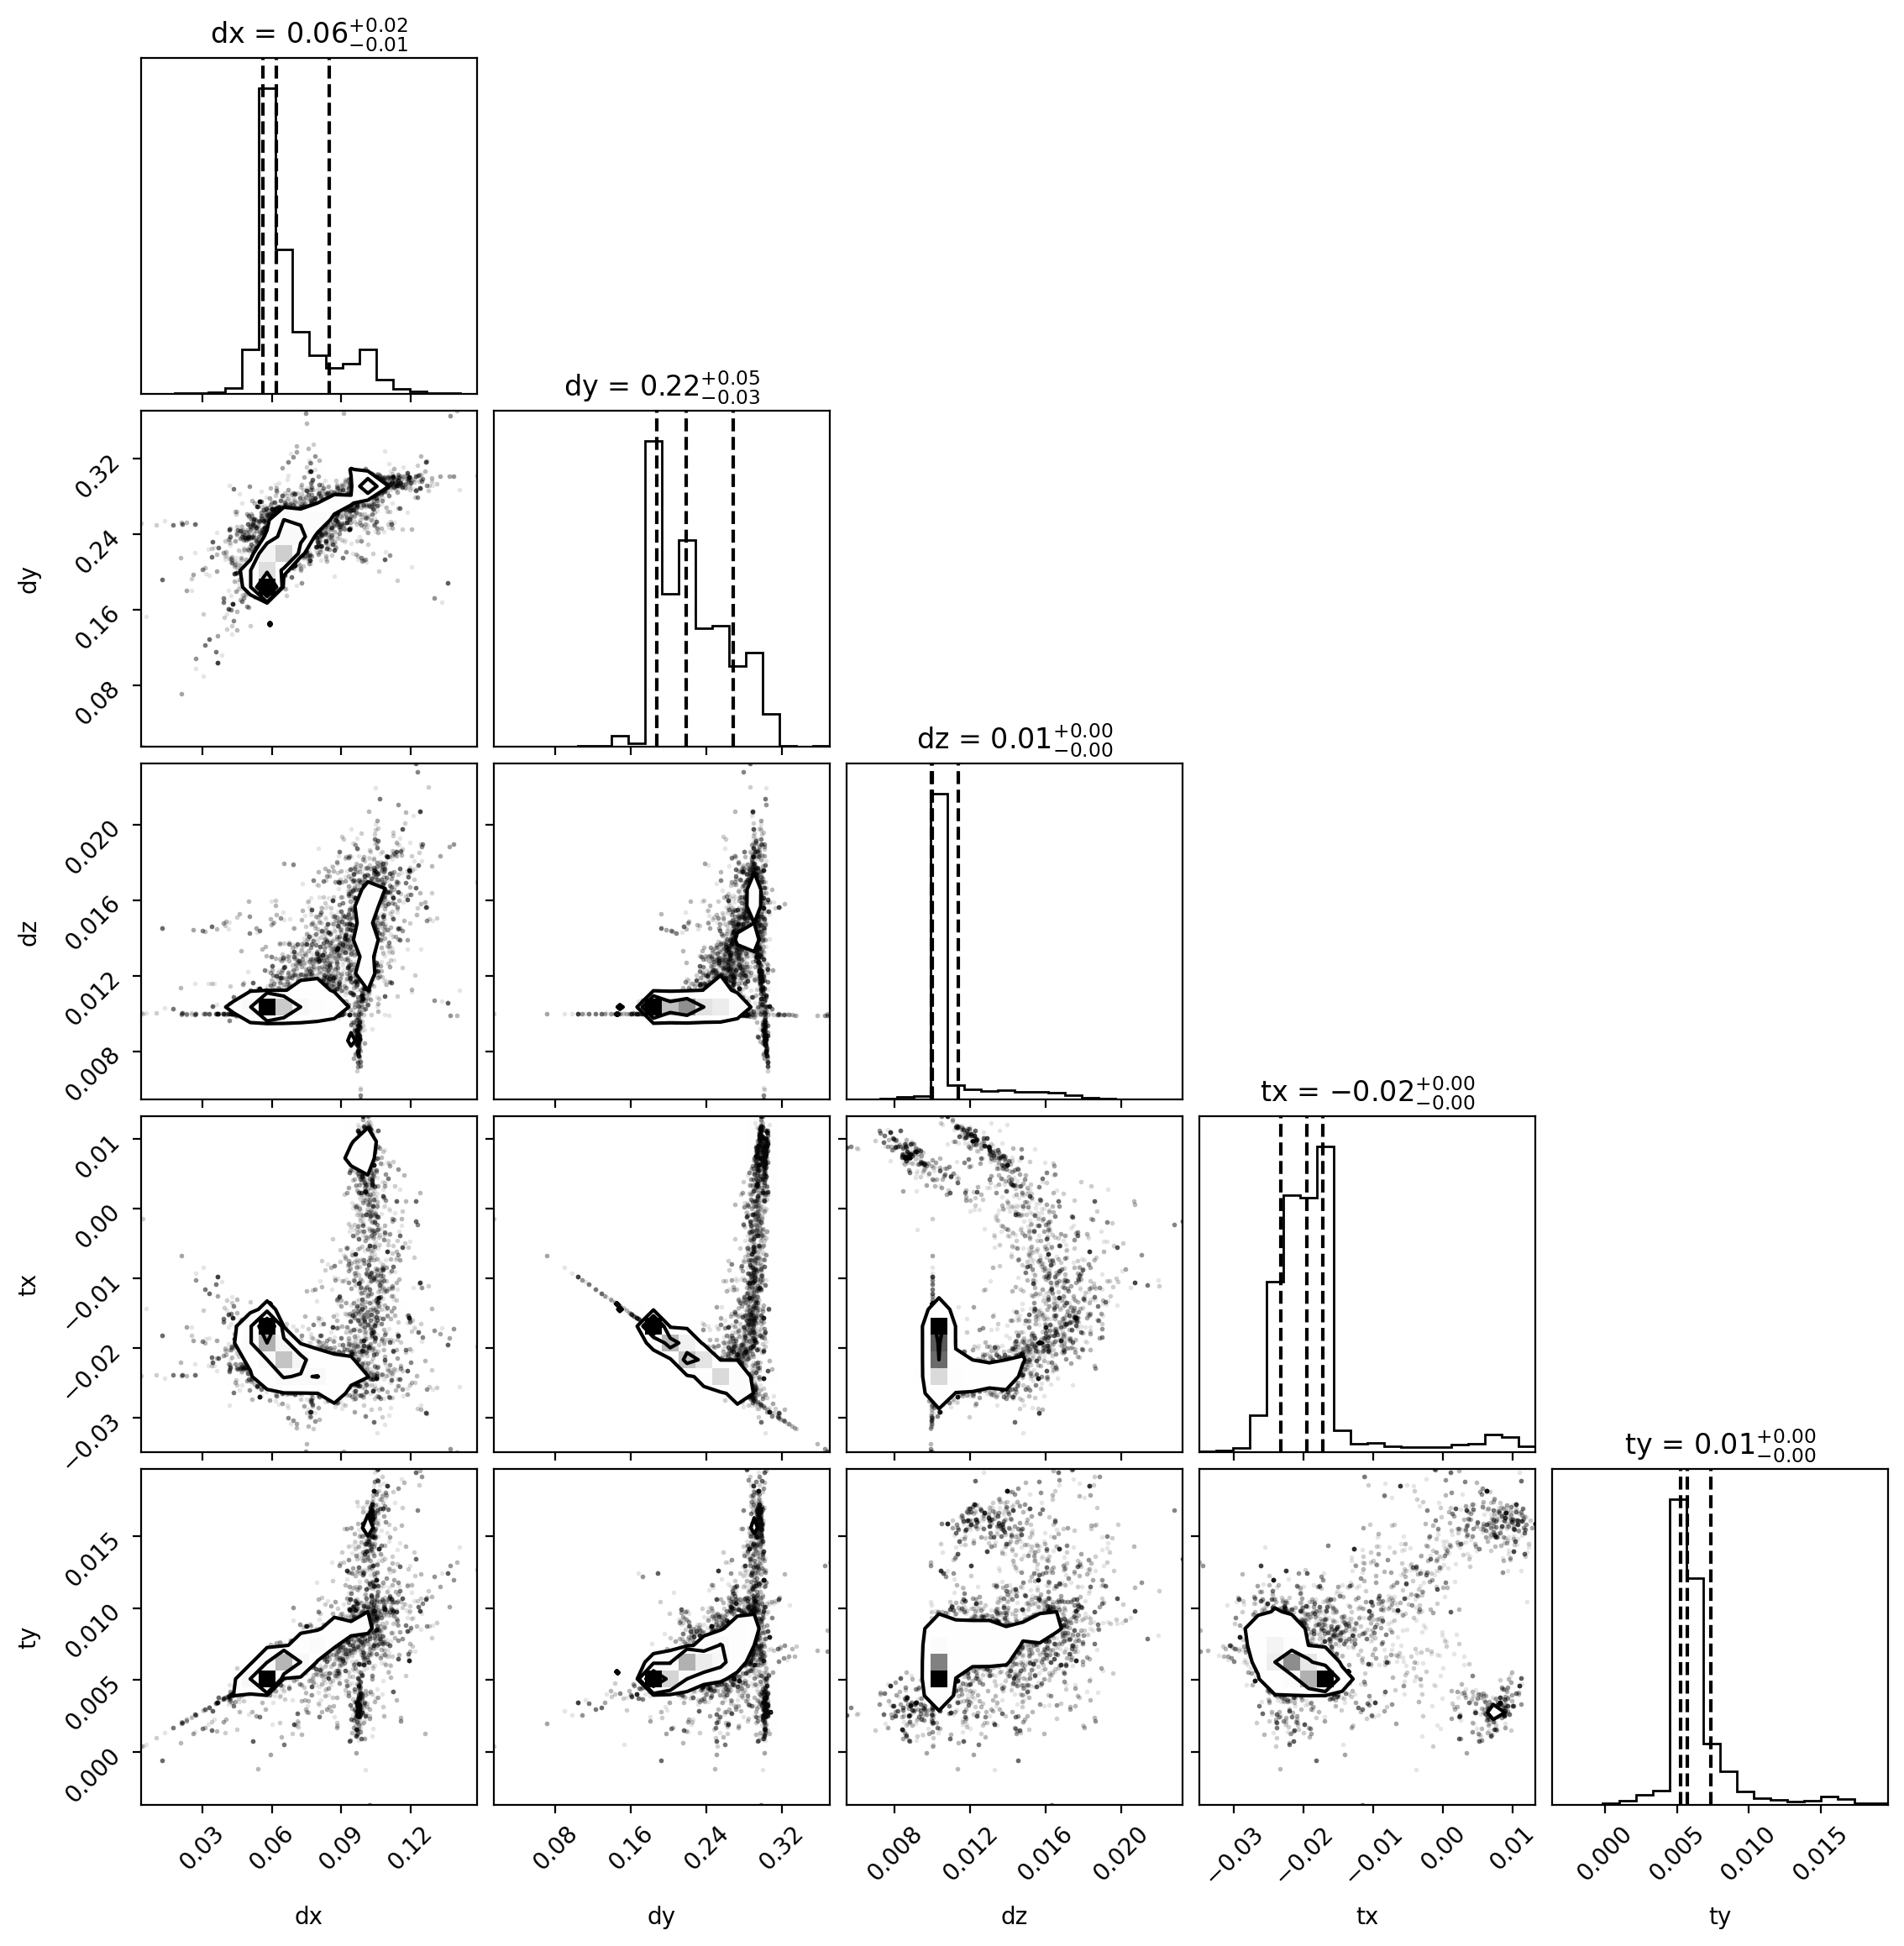

In [ ]:
samples = sampler.flatchain
labels = ['dx', 'dy', 'dz', 'tx', 'ty']
fig = corner.corner(samples,show_titles=True,labels=labels,plot_datapoints=True,quantiles=[0.16, 0.5, 0.84])

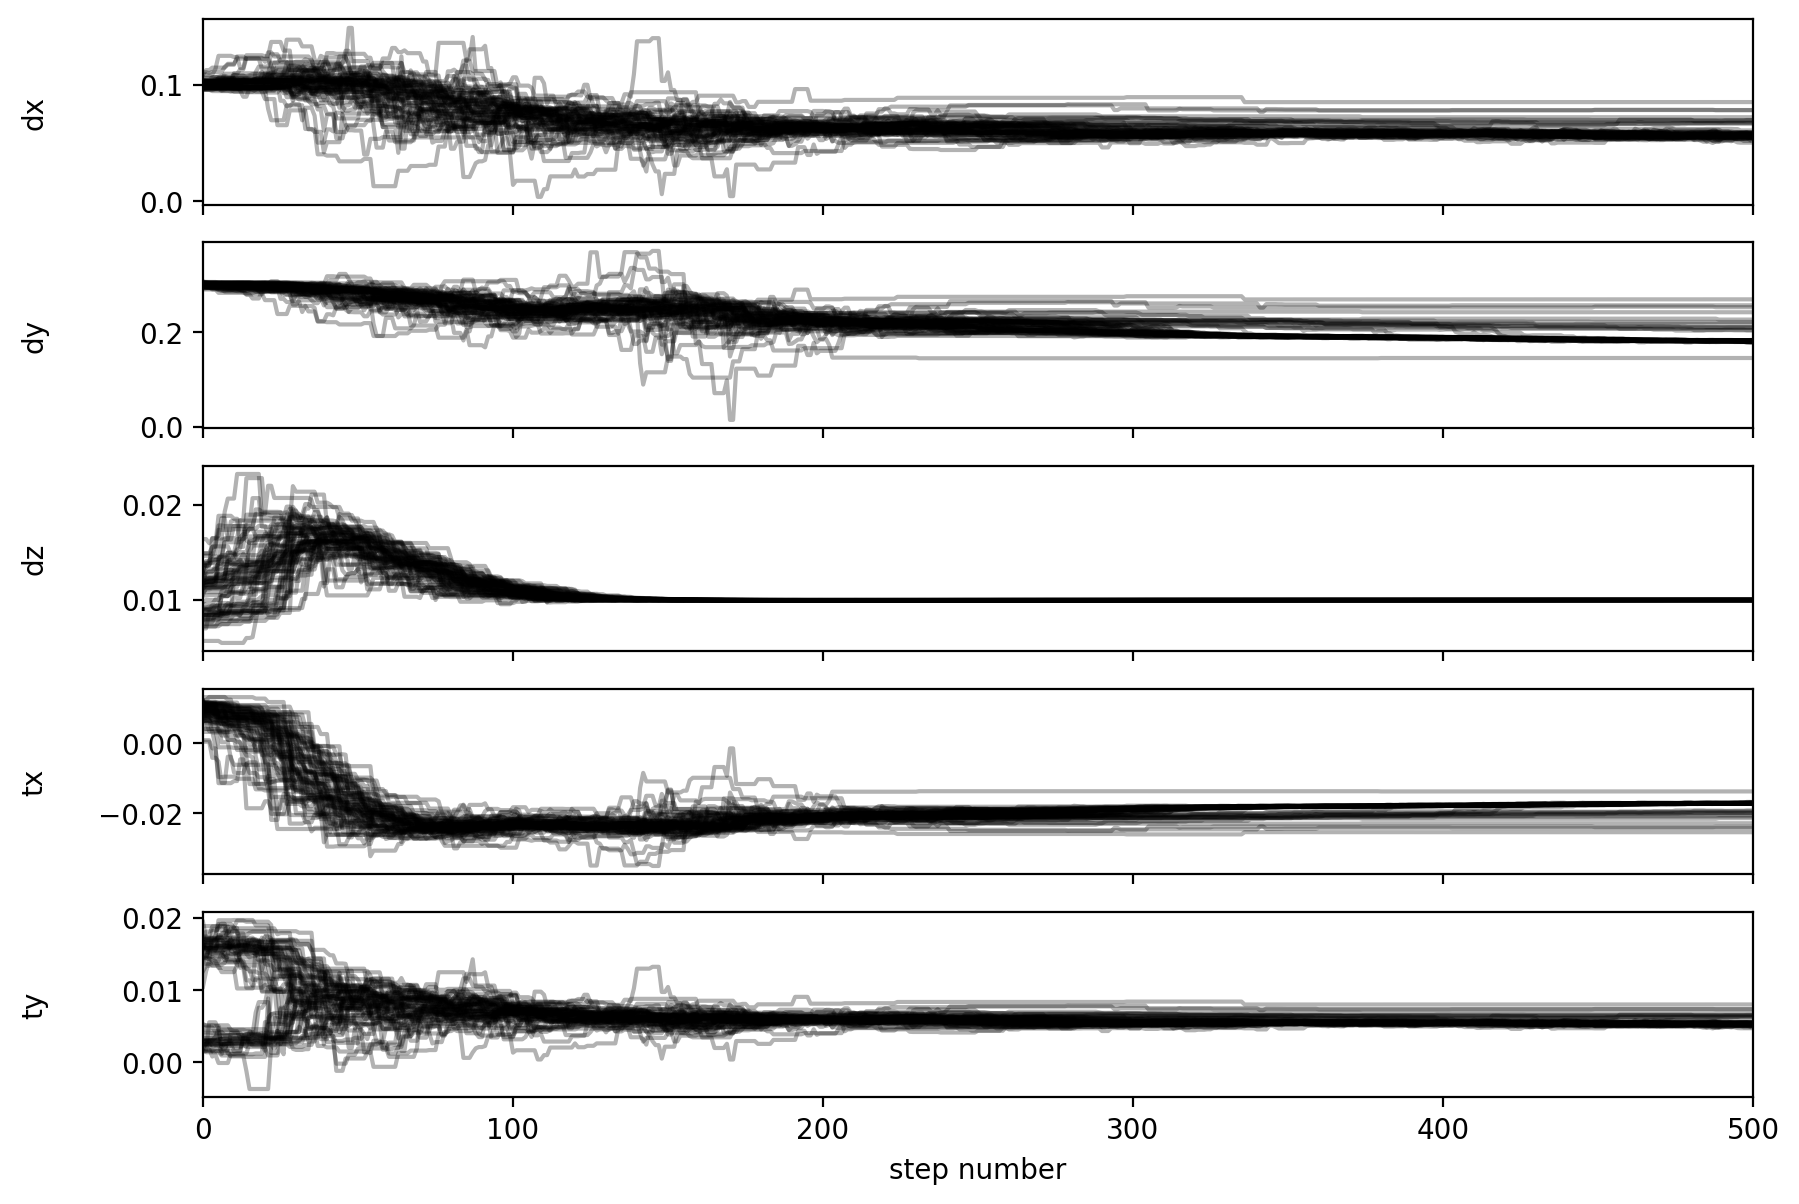

In [ ]:
fig, axes = plt.subplots(5, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["dx", "dy", "dz", "tx", "ty"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

In [143]:
if __name__ == '__main__':
    with Pool(4) as pool:
        sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob, args=data, pool=pool)

        print("Running burn-in...")
        p0, _, _ = sampler.run_mcmc(p0, 50, progress=True)
        sampler.reset()
    
        print("Running production...")
        pos, prob, state = sampler.run_mcmc(p0, niter, progress=True)

Running burn-in...


/opt/anaconda3/envs/spaceklip_new/lib/python3.11/tokenize.py:529: RuntimeWarning: coroutine 'InteractiveShell.run_cell_async' was never awaited
  pseudomatch = _compile(PseudoToken).match(line, pos)
Exception ignored in: <coroutine object InteractiveShell.run_cell_async at 0x3519a8ba0>
Traceback (most recent call last):
  File "<string>", line 1, in <lambda>
KeyError: '__import__'
Exception ignored in: <coroutine object InteractiveShell.run_cell_async at 0x3519a8ba0>
Traceback (most recent call last):
  File "<string>", line 1, in <lambda>
KeyError: '__import__'
Exception ignored in: <coroutine object InteractiveShell.run_cell_async at 0x3519a8ba0>
Traceback (most recent call last):
  File "<string>", line 1, in <lambda>
KeyError: '__import__'
Exception ignored in: <coroutine object InteractiveShell.run_cell_async at 0x3519a8ba0>/opt/anaconda3/envs/spaceklip_new/lib/python3.11/tokenize.py:529: RuntimeWarning: coroutine 'InteractiveShell.run_cell_async' was never awaited
  pseudomatch =

Running production...


100%|██████████| 500/500 [2:03:38<00:00, 14.84s/it] 


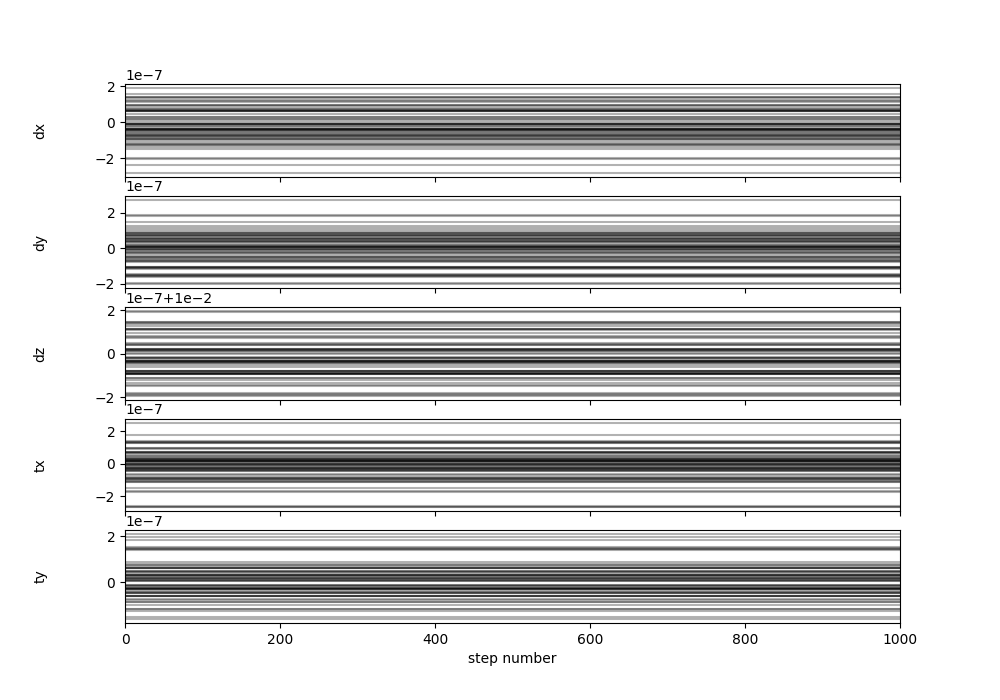

In [139]:
fig, axes = plt.subplots(5, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["dx", "dy", "dz", "tx", "ty"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

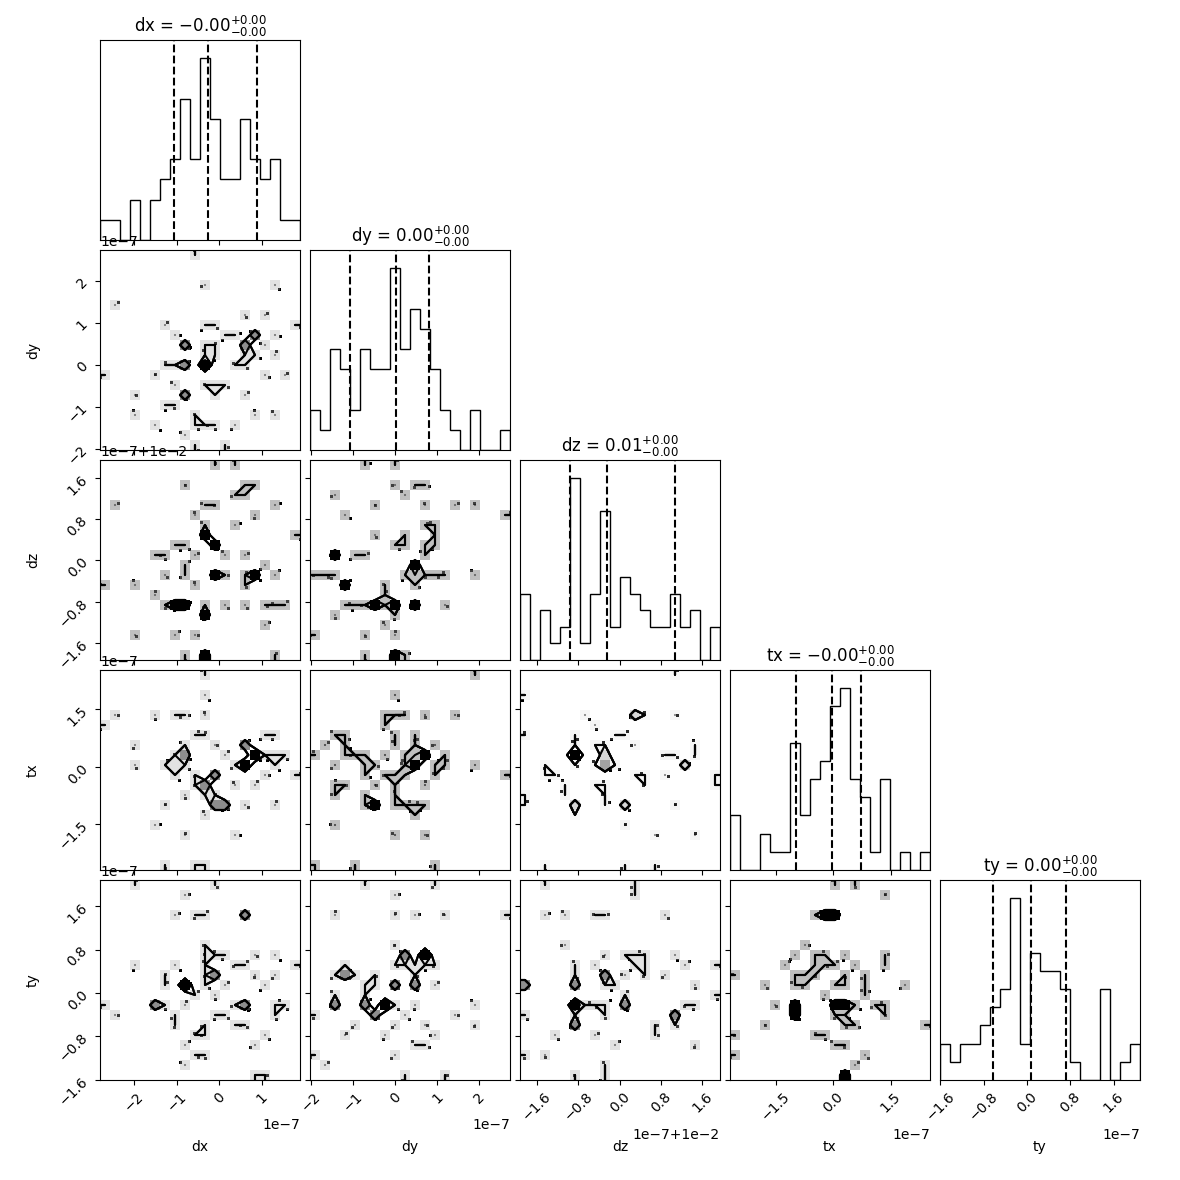

In [ ]:
samples = sampler.flatchain
labels = ['dx', 'dy', 'dz', 'tx', 'ty']
fig = corner.corner(samples,show_titles=Trueb,labels=labels,plot_datapoints=True,quantiles=[0.16, 0.5, 0.84])

/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/matplotlib/_api/__init__.py:87: RuntimeWarning: coroutine 'InteractiveShell.run_cell_async' was never awaited
  for k, v in kwargs.items():


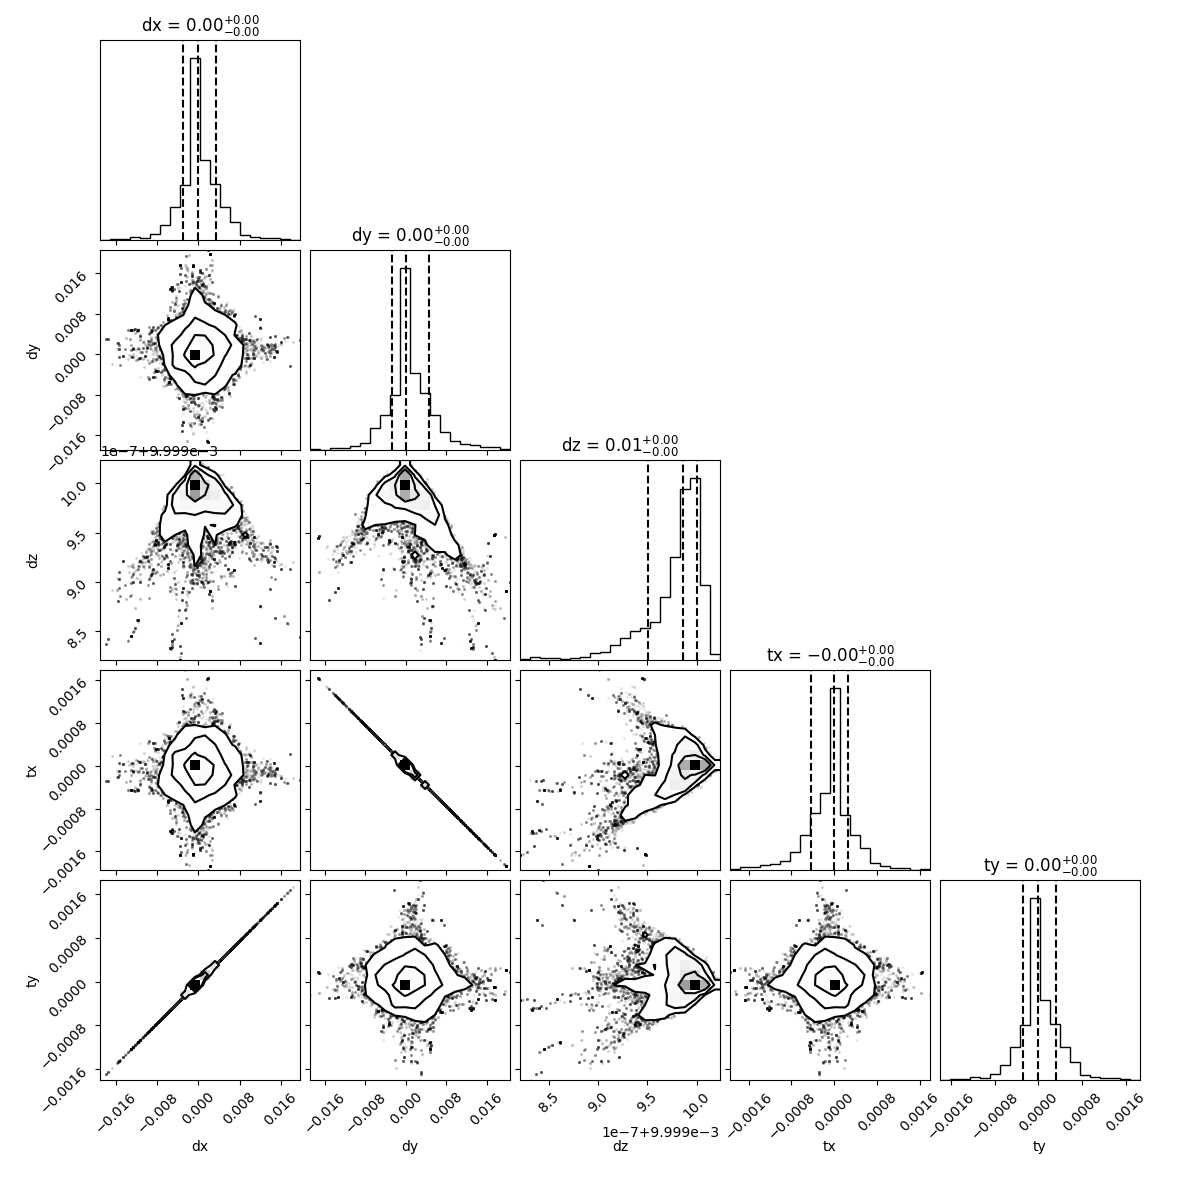

In [144]:
samples = sampler.flatchain
labels = ['dx', 'dy', 'dz', 'tx', 'ty']
fig = corner.corner(samples,show_titles=True,labels=labels,plot_datapoints=True,quantiles=[0.16, 0.5, 0.84])

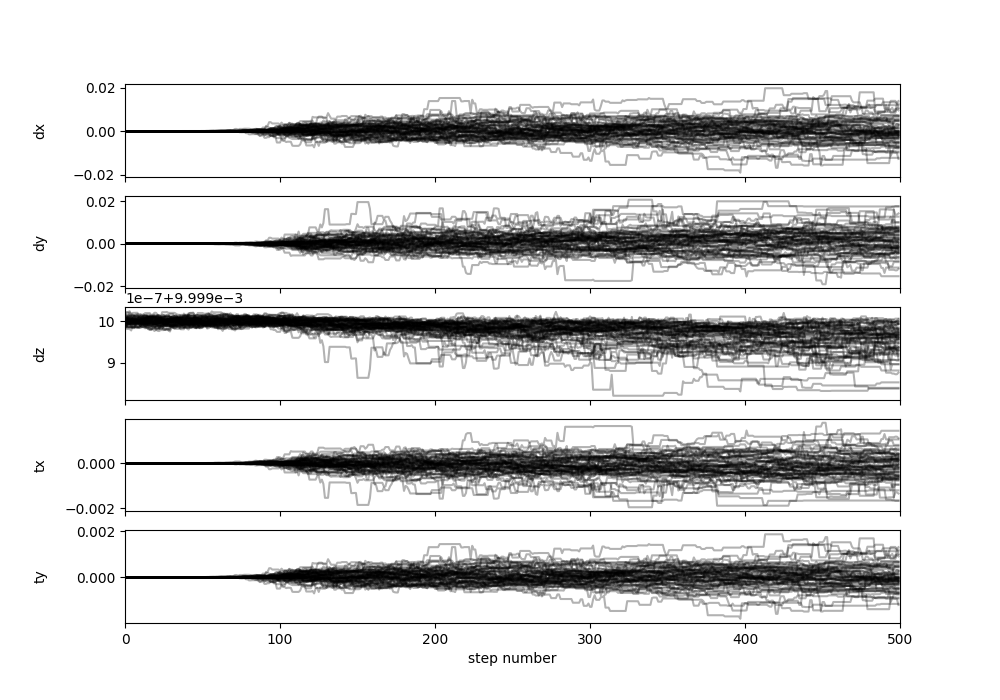

In [145]:
fig, axes = plt.subplots(5, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["dx", "dy", "dz", "tx", "ty"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

In [146]:
sampler.accepted()

AttributeError: 'EnsembleSampler' object has no attribute 'accepted'

In [172]:
sampler.backend.rejected

AttributeError: 'Backend' object has no attribute 'rejected'

In [164]:
len(sampler.backend.chain)

500

In [165]:
os.path.dirname(emcee.__file__)

'/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/emcee'

In [171]:
import emcee